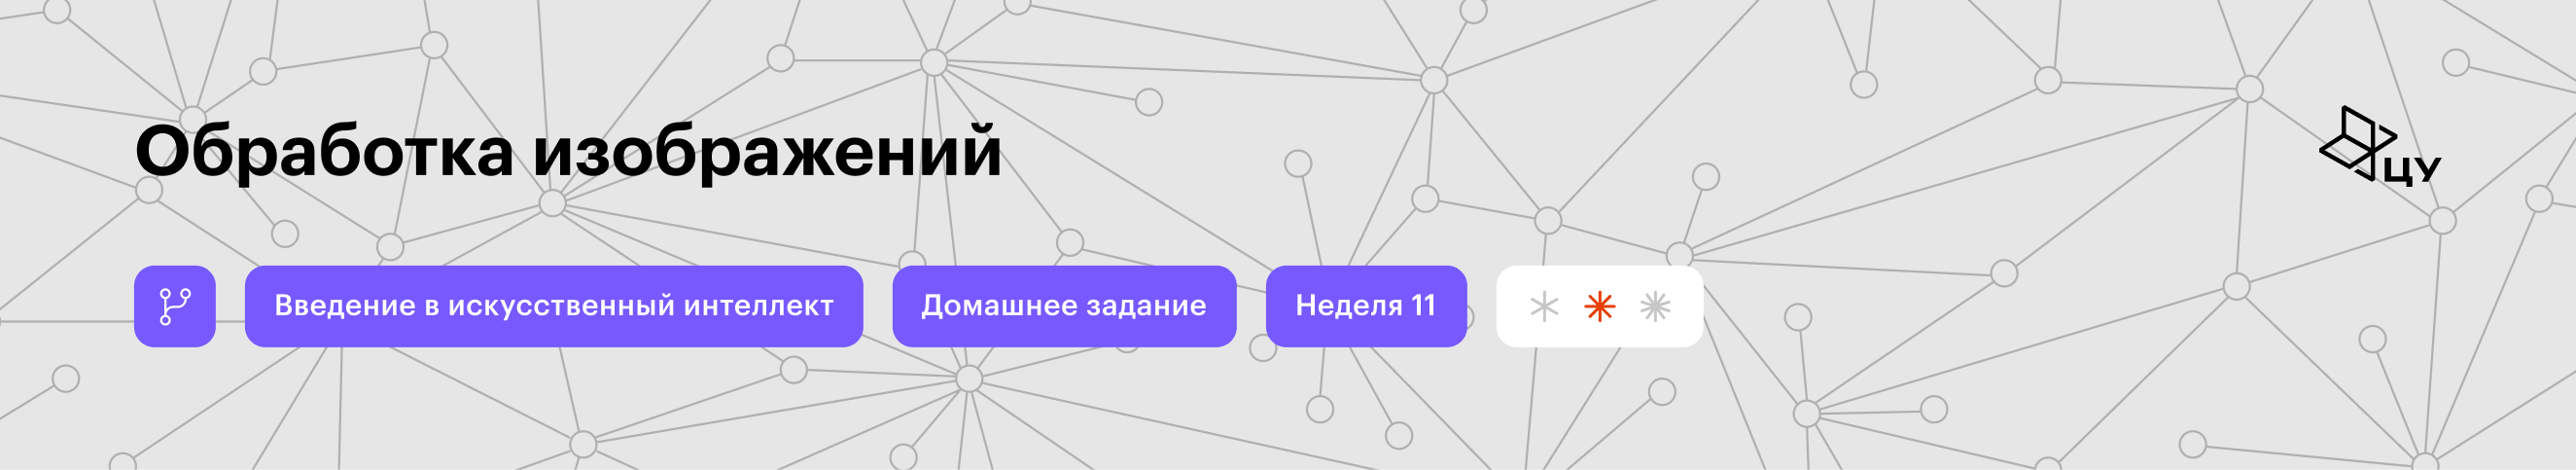

# Домашнее задание по теме «Обработка изображений»

В этом домашнем задании ты поработаешь с изображениями и исследуешь, как искажения влияют на их качество и на работу простой модели классификации.

Тебе предстоит:

- добавить к изображению Gaussian noise и Salt & Pepper noise;
- реализовать MSE, MAE и PSNR и исследовать их зависимость от уровня шума;
- применить сглаживающие фильтры и сравнить результаты визуально и с помощью метрик;
- обучить логистическую регрессию на изображениях цифр и проверить её чувствительность к сдвигу.

Всего **4 задания, 10 баллов**: 3 + 2 + 3 + 2. В эталонной версии после блоков «Твоё решение» приведены решения и выводы.


> ### Правила домашнего задания
> 1. Нельзя удалять существующие ячейки кода.
> 2. Можно добавлять и дописывать свои ячейки.
> 3. Место, куда тебе нужно написать код, помечается комментарием.
> 4. Ответ без кода, который подтвердит твоё решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется и нужно сделать вывод из известных данных.
> 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.
> 6. Все графики подписывай так, чтобы можно было легко понять их суть. Избегай слишком мелкого или крупного текста, подписывай оси на одном языке.
> 7. В выводах опирайся на полученные изображения, таблицы и графики. Для случайных преобразований фиксируй seed.


## Импорт пакетов

Ноутбук рассчитан на Python 3 и Google Colab / Jupyter. Если какой-то библиотеки нет, установи её командой `%pip install numpy pandas matplotlib opencv-python-headless scikit-learn` в отдельной ячейке.


In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['image.cmap'] = 'gray'


## Подготовка данных

В заданиях 1–3 используй одно и то же изображение `kodak/kodim07.png` из датасета Kodak, как в исходном домашнем задании по свёрткам. Ячейка ниже скачает только этот файл, если его ещё нет рядом с ноутбуком. Для первого запуска нужен интернет.

Для задания 4 используется встроенный в `sklearn` датасет `digits`; отдельно скачивать его не нужно.


In [2]:
image_path = Path('kodak/kodim07.png')
if not image_path.exists():
    image_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        'https://r0k.us/graphics/kodak/kodak/kodim07.png',
        image_path,
    )

print('Изображение для заданий 1–3:', image_path)


Изображение для заданий 1–3: kodak/kodim07.png


## Вспомогательная функция для визуализации результатов

Во всех сравнениях используй одну шкалу яркости: от 0 до 255. Функция ниже принимает numpy-массивы: grayscale или RGB. Цветное изображение, прочитанное через `cv2.imread`, перед показом нужно перевести из BGR в RGB.


In [3]:
def plot_images(images, titles=None, fontsize=13, figsize=(16, 4), save_path=None):
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for i, image in enumerate(images):
        ax = axes[0, i]
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(image)
        ax.axis('off')
        if titles is not None:
            ax.set_title(titles[i], fontsize=fontsize)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight')
    plt.show()


### Задание 1. Добавление шума к изображению [3 балла]

В этом задании тебе нужно испортить изображение двумя различными способами.

#### Часть 1. Подготовка изображения [0,6 балла]

1. Прочитай `kodak/kodim07.png` и переведи изображение в формат grayscale.
2. Визуализируй исходное изображение. Сохрани его в переменной `img_gray`: это эталон для следующих заданий.

Для визуализации можно использовать функцию `plot_images` выше.

#### Часть 2. Gaussian noise [1,2 балла]

Добавь к изображению гауссовский шум:

$$
\varepsilon \sim \mathcal{N}(0, \sigma^2),
$$

где $\sigma$ — стандартное отклонение шума. Используй значения $10$, $20$, $40$.

1. Для каждого значения $\sigma$ сгенерируй шум такого же размера, что и изображение.
2. Прибавь шум к исходному изображению. До сложения переведи изображение в вещественный тип, чтобы избежать переполнения `uint8`.
3. Ограничь значения пикселей диапазоном $[0, 255]$ и приведи результат к типу `uint8`.
4. Визуализируй результаты рядом с исходным изображением.

#### Часть 3. Salt & Pepper noise [1,2 балла]

Добавь к изображению случайные чёрные и белые пиксели. Пусть вероятность искажения пикселя равна $p$. Используй значения $0{,}01$; $0{,}03$; $0{,}1$.

1. Для каждого значения $p$ скопируй исходное изображение.
2. Независимо для каждого пикселя: с вероятностью $p/2$ замени его на $0$, с вероятностью $p/2$ — на $255$, с вероятностью $1-p$ оставь без изменений. Один пиксель не должен одновременно попадать в обе группы.
3. Визуализируй результаты рядом с исходным изображением.

### Что должно получиться

Сохрани результаты в словари `gaussian_images` (ключ — $\sigma$) и `sp_images` (ключ — $p$). Добавь в каждый словарь уровень `0`, соответствующий копии исходного изображения без шума. Эти же массивы понадобятся в заданиях 2 и 3: заново генерировать шум там не нужно.

Для дальнейшего сравнения сохрани `gauss_noisy = gaussian_images[40]` и `sp_noisy = sp_images[0.1]`.

Кратко сравни, как визуально отличаются два типа шума и что меняется при увеличении его уровня.


#### Твоё решение


BGR: (512, 768, 3) uint8
grayscale: (512, 768) uint8


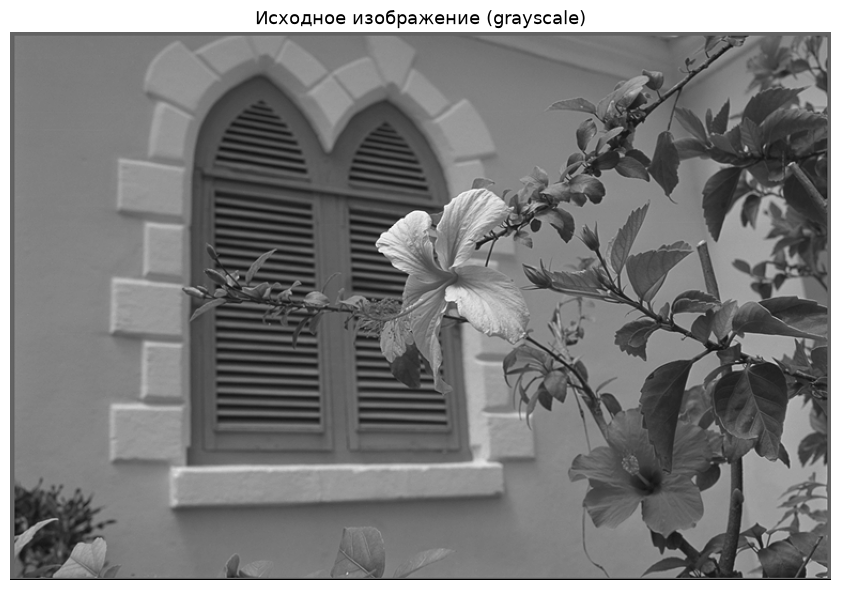

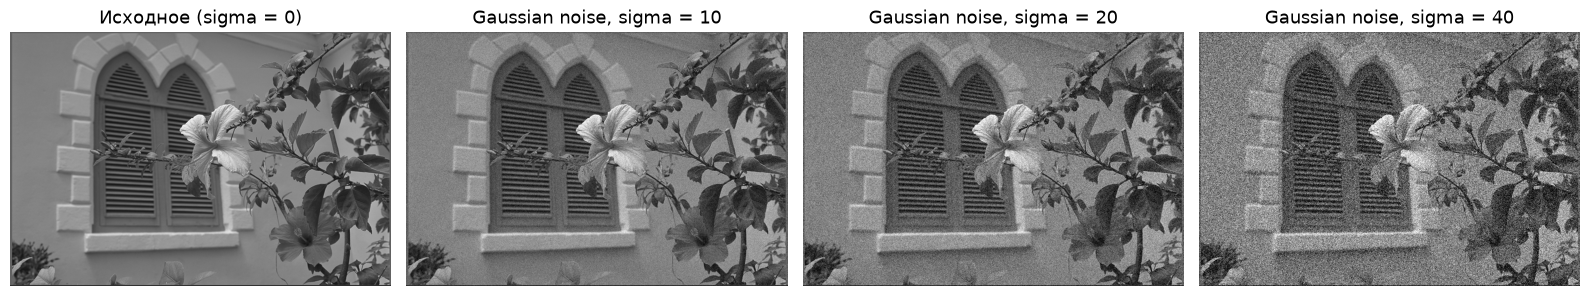

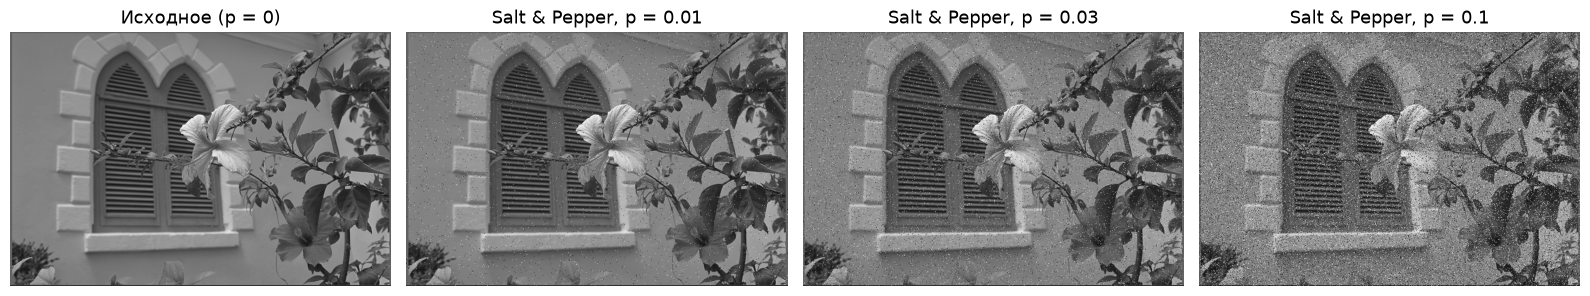

In [4]:
img = cv2.imread(str(image_path))

print('BGR:', img.shape, img.dtype)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print('grayscale:', img_gray.shape, img_gray.dtype)

plot_images([img_gray], ['Исходное изображение (grayscale)'], figsize=(9, 6))

rng = np.random.default_rng(SEED)
SIGMAS = [10, 20, 40]

gaussian_images = {0: img_gray.copy()}

for sigma in SIGMAS:
    noise = rng.normal(0, sigma, size=img_gray.shape)
    noisy = img_gray.astype(np.float64) + noise
    noisy = np.clip(noisy, 0, 255).astype(np.uint8)
    gaussian_images[sigma] = noisy

plot_images(
    [gaussian_images[s] for s in [0] + SIGMAS],
    ['Исходное (sigma = 0)'] + [f'Gaussian noise, sigma = {sigma}' for sigma in SIGMAS],
)

rng = np.random.default_rng(SEED + 1)
PS = [0.01, 0.03, 0.1]

sp_images = {0: img_gray.copy()}

for p in PS:
    noisy = img_gray.copy()
    rand = rng.random(img_gray.shape)
    noisy[rand < p / 2] = 0
    noisy[(rand >= p / 2) & (rand < p)] = 255
    sp_images[p] = noisy

plot_images(
    [sp_images[p] for p in [0] + PS],
    ['Исходное (p = 0)'] + [f'Salt & Pepper, p = {p}' for p in PS],
)

gauss_noisy = gaussian_images[40]
sp_noisy = sp_images[0.1]


гауссовский шум трясёт всю картинку: при sigma = 40 мелкие детали уже тонут в шуме. salt & pepper только выбивает отдельные пиксели: при p = 0.1 их полно, но контуры остаются чёткими.


### Задание 2. Метрики качества изображения и их зависимость от шума [2 балла]

Используй **те же** `img_gray`, `gaussian_images` и `sp_images`, которые получились в задании 1. Во всех сравнениях эталоном служит исходное изображение `img_gray`.

#### Часть 1. Реализация метрик [0,9 балла]

Самостоятельно реализуй три функции: `mse(reference, image)`, `mae(reference, image)`, `psnr(reference, image)` — по **0,3 балла** за каждую. Готовые реализации метрик использовать нельзя; операции NumPy использовать можно.

Для изображений $I$ и $J$ одинакового размера, содержащих $N$ значений пикселей:

$$
\operatorname{MSE}(I,J) = \frac{1}{N}\sum_{i=1}^{N}(I_i-J_i)^2,
$$

$$
\operatorname{MAE}(I,J) = \frac{1}{N}\sum_{i=1}^{N}|I_i-J_i|,
$$

$$
\operatorname{PSNR}(I,J) = 10\log_{10}\left(\frac{255^2}{\operatorname{MSE}(I,J)}\right).
$$

Вычисления веди в вещественном типе: вычитание массивов `uint8` приводит к переполнению. Здесь изображения имеют диапазон $[0,255]$, поэтому максимум в формуле PSNR всегда равен **255**, а не максимуму конкретного изображения. PSNR измеряется в децибелах (дБ).

Если MSE равна нулю, PSNR должна возвращать `np.inf`.

#### Часть 2. Проверка и сравнение изображений [0,3 балла]

1. Проверь метрики на паре одинаковых изображений: ожидаются MSE = 0, MAE = 0, PSNR = ∞.
2. Посчитай все три метрики для изображений `gauss_noisy` и `sp_noisy` относительно `img_gray`. Выведи результаты в таблице. Для каких метрик меньшее значение означает лучшее качество, а для какой — большее?

#### Часть 3. Зависимость от уровня шума [0,5 балла]

1. Посчитай MSE, MAE и PSNR для **всех** уровней шума из задания 1, включая уровень 0, и собери общую таблицу.
2. Для каждого типа шума построй три графика: MSE, MAE и PSNR от уровня шума. Для Gaussian noise по оси X отложи $\sigma$, для Salt & Pepper noise — $p$.
3. Бесконечное значение PSNR при нулевом шуме оставь в таблице, но не соединяй с конечными точками графика.

#### Часть 4. Анализ результатов [0,3 балла]

Ответь на вопросы.

- Как меняются MSE, MAE и PSNR при увеличении уровня каждого из двух типов шума?
- Почему при увеличении ошибки PSNR уменьшается?
- Совпадает ли численная оценка качества с визуальной? Достаточно ли одного числа, чтобы понять, какие детали изображения испорчены?

Сравнивать σ и p напрямую нельзя: это разные параметры, заданные в разных единицах. Исследуй зависимость отдельно для каждого типа шума.


#### Твоё решение


MSE(img_gray, img_gray)  = 0.0
MAE(img_gray, img_gray)  = 0.0
PSNR(img_gray, img_gray) = inf


,Изображение,MSE,MAE,"PSNR, дБ"
0,"Gaussian noise, sigma = 40",1527.93,31.34,16.29
1,"Salt & Pepper, p = 0.1",1803.77,12.81,15.57


,Тип шума,Уровень,MSE,MAE,"PSNR, дБ"
0,Gaussian,0.00,0.00,0.00,inf
1,Gaussian,10.00,100.33,7.98,28.12
2,Gaussian,20.00,397.65,15.91,22.14
3,Gaussian,40.00,1527.93,31.34,16.29
4,Salt & Pepper,0.00,0.00,0.00,inf
5,Salt & Pepper,0.01,183.38,1.29,25.50
6,Salt & Pepper,0.03,530.10,3.77,20.89
7,Salt & Pepper,0.10,1803.77,12.81,15.57


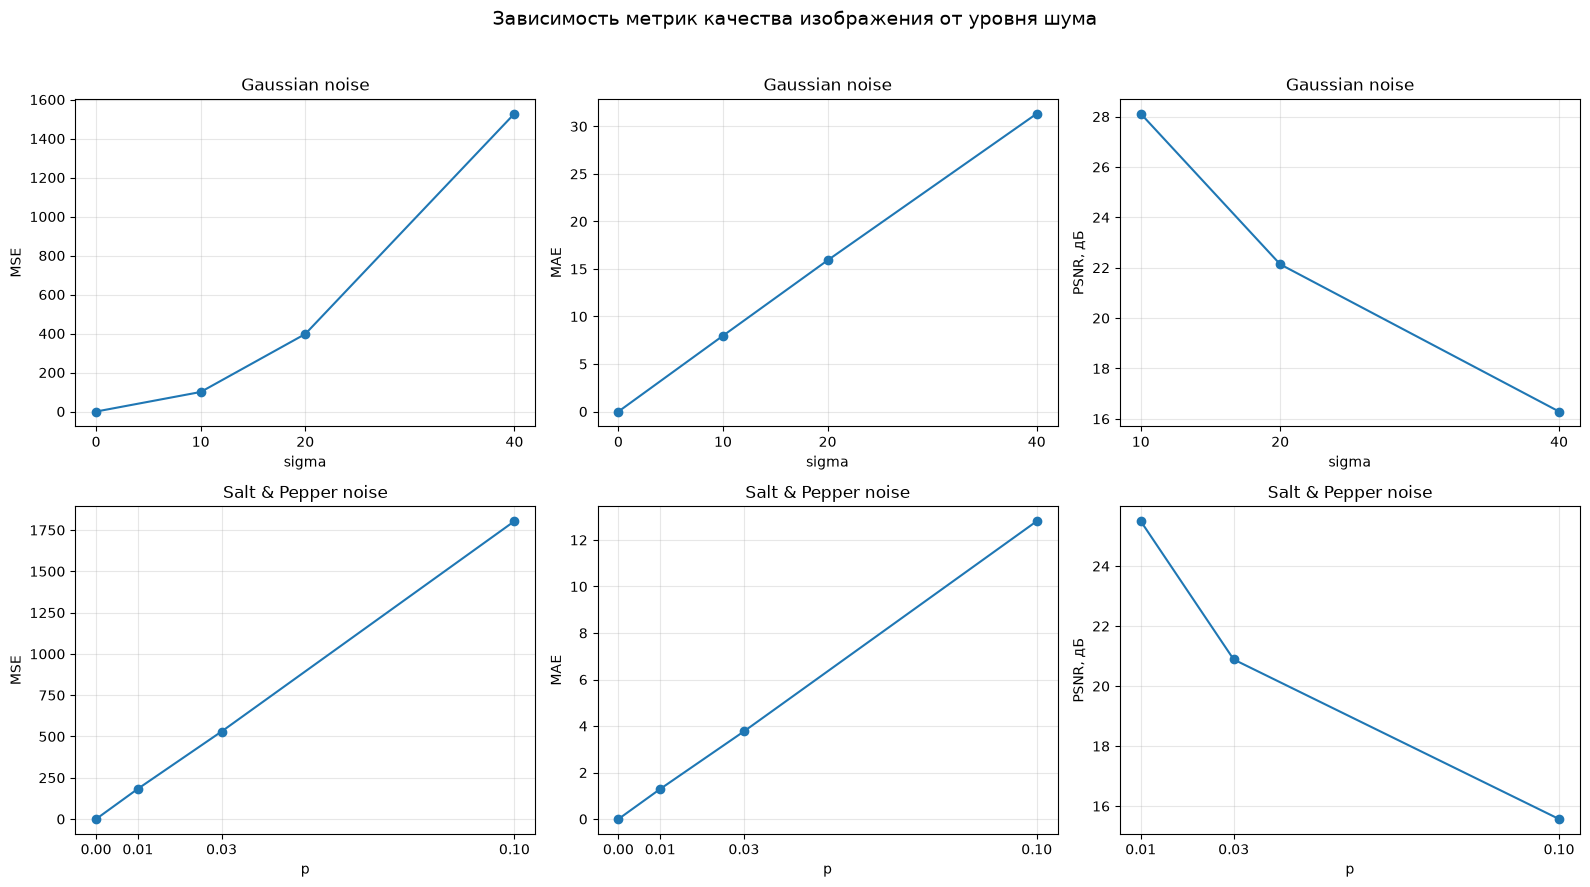

In [5]:
def mse(reference, image):
    diff = reference.astype(np.float64) - image.astype(np.float64)
    return np.mean(diff ** 2)


def mae(reference, image):
    diff = reference.astype(np.float64) - image.astype(np.float64)
    return np.mean(np.abs(diff))


def psnr(reference, image):
    err = mse(reference, image)
    if err == 0:
        return np.inf
    return 10 * np.log10(255.0 ** 2 / err)

metric_cases = [
    (np.array([1, 2]), np.array([2, 4]), 2.5, 1.5),
    (np.array([0, 0]), np.array([255, 255]), 255.0 ** 2, 255.0),
]

for ref, image, exp_mse, exp_mae in metric_cases:
    assert abs(mse(ref, image) - exp_mse) < 1e-9, f'{mse(ref, image)} != {exp_mse}'
    assert abs(mae(ref, image) - exp_mae) < 1e-9, f'{mae(ref, image)} != {exp_mae}'
    assert abs(psnr(ref, image) - 10 * np.log10(255.0 ** 2 / exp_mse)) < 1e-9

print('MSE(img_gray, img_gray)  =', mse(img_gray, img_gray))
print('MAE(img_gray, img_gray)  =', mae(img_gray, img_gray))
print('PSNR(img_gray, img_gray) =', psnr(img_gray, img_gray))

rows = []
for name, noisy in [('Gaussian noise, sigma = 40', gauss_noisy),
                    ('Salt & Pepper, p = 0.1', sp_noisy)]:
    rows.append({'Изображение': name,
                 'MSE': mse(img_gray, noisy),
                 'MAE': mae(img_gray, noisy),
                 'PSNR, дБ': psnr(img_gray, noisy)})

metrics_table = pd.DataFrame(rows)
display(metrics_table.round(2))

rows = []
for sigma in sorted(gaussian_images):
    noisy = gaussian_images[sigma]
    rows.append({'Тип шума': 'Gaussian', 'Уровень': sigma,
                 'MSE': mse(img_gray, noisy), 'MAE': mae(img_gray, noisy),
                 'PSNR, дБ': psnr(img_gray, noisy)})
for p in sorted(sp_images):
    noisy = sp_images[p]
    rows.append({'Тип шума': 'Salt & Pepper', 'Уровень': p,
                 'MSE': mse(img_gray, noisy), 'MAE': mae(img_gray, noisy),
                 'PSNR, дБ': psnr(img_gray, noisy)})

metrics_all = pd.DataFrame(rows)
display(metrics_all.round(2))

metrics_for_plot = [('MSE', mse), ('MAE', mae), ('PSNR, дБ', psnr)]
noises = [('Gaussian noise', gaussian_images, 'sigma'), ('Salt & Pepper noise', sp_images, 'p')]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, (noise_name, images_dict, xlabel) in enumerate(noises):
    levels = sorted(images_dict)
    for col, (metric_name, metric_fn) in enumerate(metrics_for_plot):
        ax = axes[row, col]
        plot_levels = levels if metric_name != 'PSNR, дБ' else levels[1:]
        values = [metric_fn(img_gray, images_dict[level]) for level in plot_levels]
        ax.plot(plot_levels, values, marker='o')
        ax.set_title(noise_name)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(metric_name)
        ax.set_xticks(plot_levels)
        ax.grid(alpha=0.3)
fig.suptitle('Зависимость метрик качества изображения от уровня шума', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


чем больше шум, тем хуже метрики: mse растёт (у гаусса примерно как sigma^2), psnr падает. число с глазами совпадает не всегда: у salt & pepper mse хуже, но выглядит картинка приличнее.


### Задание 3. Удаление шума [3 балла]

В этом задании тебе нужно убрать шум с изображений из задания 1: `gauss_noisy` ($\sigma=40$) и `sp_noisy` ($p=0{,}1$). Используй сохранённые массивы, чтобы все фильтры сравнивались на одинаковых искажениях.

#### Часть 1. Применение фильтров [1,5 балла]

Примени минимум три фильтра из списка — **по 0,5 балла за каждый**:

- Mean filter (`cv2.blur`);
- Gaussian filter (`cv2.GaussianBlur`);
- Median filter (`cv2.medianBlur`);
- Bilateral filter (`cv2.bilateralFilter`) — по желанию, без дополнительных баллов.

Для каждого выбранного фильтра:

- подбери параметры (размер ядра, σ и так далее); попробуй хотя бы два набора параметров;
- примени фильтр к **обоим** зашумлённым изображениям;
- визуализируй выбранный результат рядом с исходным и зашумлённым изображением;
- посчитай MSE, MAE и PSNR из задания 2 относительно `img_gray`.

При подборе параметров можно ориентироваться на MSE: это учебный эксперимент с доступным исходным изображением. Включи в итоговую таблицу также строку «Без фильтра», чтобы было видно, улучшилось ли качество. Лучшие параметры для двух типов шума могут различаться.

#### Часть 2. Сравнение результатов [1,5 балла]

Ответь на вопросы, используя изображения и таблицу метрик.

1. **[0,4 балла]** Какой фильтр лучше справился с Gaussian noise по MSE/PSNR? Совпадает ли вывод с визуальной оценкой?
2. **[0,4 балла]** Какой фильтр лучше справился с Salt & Pepper noise? Почему?
3. **[0,4 балла]** Какие фильтры сильнее размывают детали? Может ли уменьшение численной ошибки сопровождаться потерей мелких деталей?
4. **[0,3 балла]** Легко ли было подобрать параметры? Что меняется при увеличении размера ядра?


#### Твоё решение


,Шум,Фильтр,Параметры,MSE,MAE,"PSNR, дБ"
0,"Gaussian, sigma = 40",Без фильтра,-,1527.93,31.34,16.29
1,"Gaussian, sigma = 40",Mean filter,ядро 3x3,219.97,11.53,24.71
2,"Gaussian, sigma = 40",Mean filter,ядро 7x7,211.92,9.66,24.87
3,"Gaussian, sigma = 40",Gaussian filter,ядро 5x5,171.97,10.03,25.78
4,"Gaussian, sigma = 40",Gaussian filter,ядро 9x9,161.58,8.81,26.05
5,"Gaussian, sigma = 40",Median filter,ядро 3x3,307.59,13.86,23.25
6,"Gaussian, sigma = 40",Median filter,ядро 7x7,203.78,10.00,25.04
7,"Gaussian, sigma = 40",Bilateral filter,"d=9, sigma=75",209.64,10.95,24.92
8,"Gaussian, sigma = 40",Bilateral filter,"d=15, sigma=100",247.13,10.98,24.20
9,"Salt & Pepper, p = 0.1",Без фильтра,-,1803.77,12.81,15.57


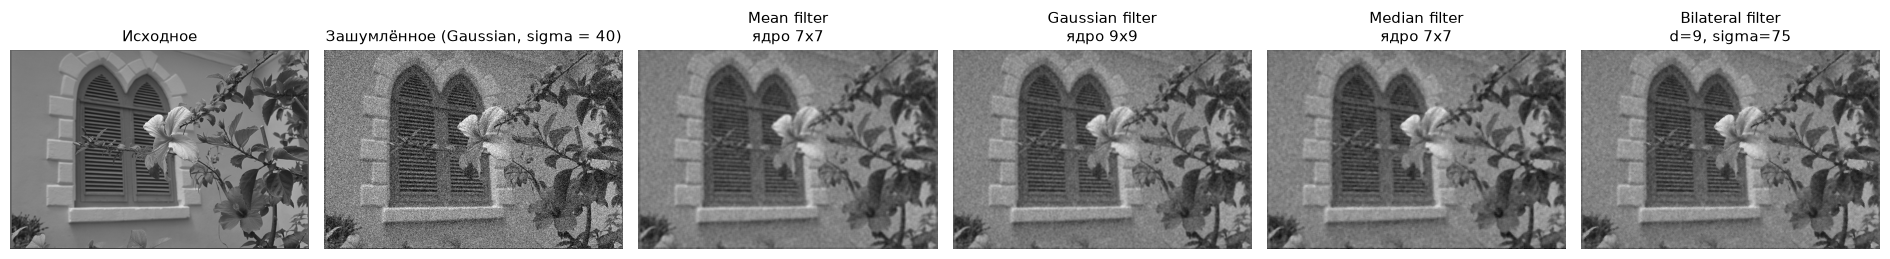

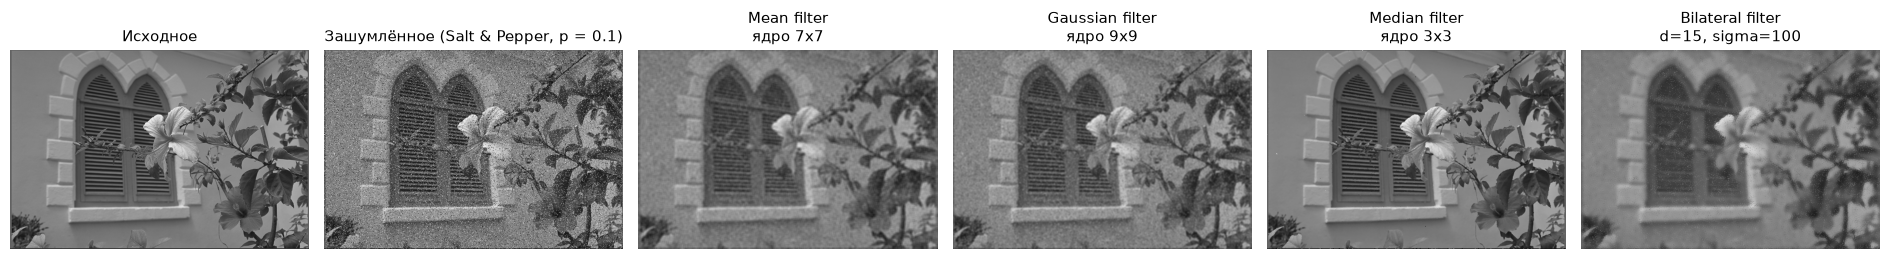

In [6]:
experiments = [
    ('Без фильтра', '-', lambda image: image.copy()),
    ('Mean filter', 'ядро 3x3', lambda image: cv2.blur(image, (3, 3))),
    ('Mean filter', 'ядро 7x7', lambda image: cv2.blur(image, (7, 7))),
    ('Gaussian filter', 'ядро 5x5', lambda image: cv2.GaussianBlur(image, (5, 5), 0)),
    ('Gaussian filter', 'ядро 9x9', lambda image: cv2.GaussianBlur(image, (9, 9), 0)),
    ('Median filter', 'ядро 3x3', lambda image: cv2.medianBlur(image, 3)),
    ('Median filter', 'ядро 7x7', lambda image: cv2.medianBlur(image, 7)),
    ('Bilateral filter', 'd=9, sigma=75', lambda image: cv2.bilateralFilter(image, 9, 75, 75)),
    ('Bilateral filter', 'd=15, sigma=100', lambda image: cv2.bilateralFilter(image, 15, 100, 100)),
]

noisy_variants = {
    'Gaussian, sigma = 40': gauss_noisy,
    'Salt & Pepper, p = 0.1': sp_noisy,
}

filtered_cache = {}
rows = []
for noise_name, noisy in noisy_variants.items():
    for name, params, filter_fn in experiments:
        filtered = filter_fn(noisy)
        filtered_cache[(noise_name, name, params)] = filtered
        rows.append({'Шум': noise_name,
                     'Фильтр': name,
                     'Параметры': params,
                     'MSE': mse(img_gray, filtered),
                     'MAE': mae(img_gray, filtered),
                     'PSNR, дБ': psnr(img_gray, filtered)})

filter_metrics = pd.DataFrame(rows)
display(filter_metrics.round(2))

filter_names = ['Mean filter', 'Gaussian filter', 'Median filter', 'Bilateral filter']

for noise_name, noisy in noisy_variants.items():
    images = [img_gray, noisy]
    titles = ['Исходное', f'Зашумлённое ({noise_name})']
    for name in filter_names:
        candidates = [e for e in experiments if e[0] == name]
        best = min(candidates,
                   key=lambda e: mse(img_gray, filtered_cache[(noise_name, e[0], e[1])]))
        images.append(filtered_cache[(noise_name, best[0], best[1])])
        titles.append(f'{best[0]}\n{best[1]}')
    plot_images(images, titles, fontsize=11, figsize=(19, 4.5))


на гауссовском шуме лучше всех gaussian 9x9 (psnr 26 дБ), на salt & pepper - median 3x3 (mse 36.3, картинка почти чистая). но лучший по mse не значит лучший на глаз: большие ядра заодно замыливают детали.


### Задание 4. Логистическая регрессия на `flatten` и чувствительность к сдвигу [2 балла]

Теперь перейди от обработки изображения к распознаванию рукописных цифр. В этом задании ты проверишь, насколько модель чувствительна к положению объекта на изображении.

Используй встроенный датасет `digits` из `sklearn` и оставь только цифры `3` и `8`. Каждое изображение имеет размер `8 × 8`, а яркость пикселей лежит в диапазоне `[0, 16]`. В готовой ячейке ниже данные уже нормированы в диапазон `[0, 1]` и подготовлены в двух формах:

- `X_img` — изображения размера `8 × 8`;
- `X_flat` — те же изображения, развёрнутые в векторы длины `64`;
- `y` — соответствующие метки классов.

Обучи логистическую регрессию на признаках `flatten`.

Выполни следующие шаги.

1. **[0,1 балла]** Разбей данные на train и test (`test_size=0.25`, `stratify=y`, `random_state=42`). Разделяй `X_img`, `X_flat` и `y` совместно, чтобы изображения и метки оставались согласованными.
2. **[0,4 балла]** Обучи `LogisticRegression` на `X_train_flat`. Установи `max_iter=2000` и `random_state=42`.
3. **[0,2 балла]** Посчитай accuracy на обычном тесте.
4. **[0,3 балла]** Создай новую версию тестовых изображений: сдвинь каждую цифру вправо на один пиксель с заполнением освободившегося столбца нулями. Правый столбец обрежь. Не используй циклический перенос пикселей.
5. **[0,2 балла]** Снова посчитай accuracy той же обученной модели — уже на сдвинутом тесте. Метки классов остаются прежними; переобучать модель не нужно.
6. **[0,3 балла]** Построй матрицы ошибок (`confusion matrix`) для обычного и сдвинутого теста.
7. **[0,1 балла]** Покажи несколько примеров ошибок на сдвинутом тесте. Подпиши истинный и предсказанный классы.

**[0,4 балла]** После этого ответь на вопросы.

- Почему модель на `flatten` может хорошо работать на исходных изображениях?
- Как изменилось качество после сдвига? Почему даже сдвиг на один пиксель может ухудшить распознавание, хотя человек по-прежнему видит ту же цифру?
- Какую информацию сохраняет представление `flatten` и почему оно чувствительно к положению штрихов?

In [7]:
# Подготовка данных для задания 4: эта ячейка уже готова
digits = load_digits()
selected_classes = [3, 8]
mask = np.isin(digits.target, selected_classes)

X_img = digits.images[mask].astype(np.float64) / 16.0
y = digits.target[mask]
X_flat = X_img.reshape(len(X_img), -1)

print("Форма массива изображений:", X_img.shape)
print("Форма массива flatten-признаков:", X_flat.shape)
print("Классы:", np.unique(y))

Форма массива изображений: (357, 8, 8)
Форма массива flatten-признаков: (357, 64)
Классы: [3 8]


#### Твоё решение

Accuracy на исходном тесте: 0.978
Accuracy на сдвинутом тесте (сдвиг вправо на 1 px): 0.656


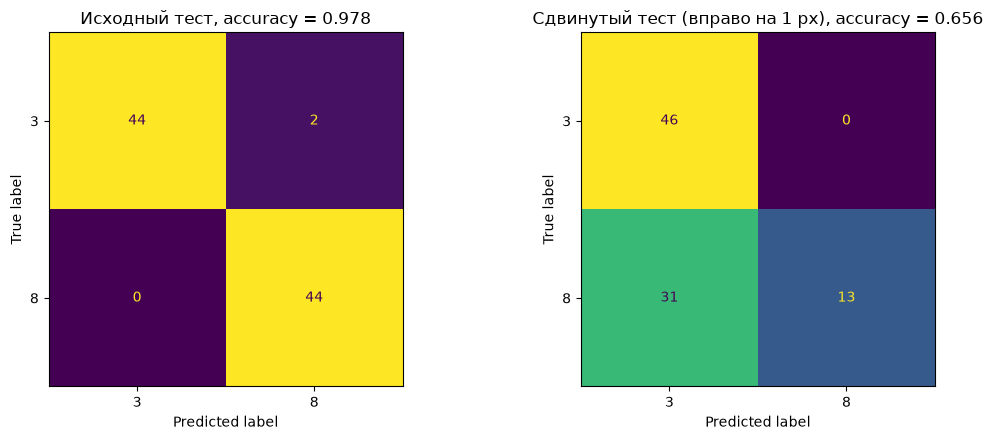

Ошибок на сдвинутом тесте: 31 из 90


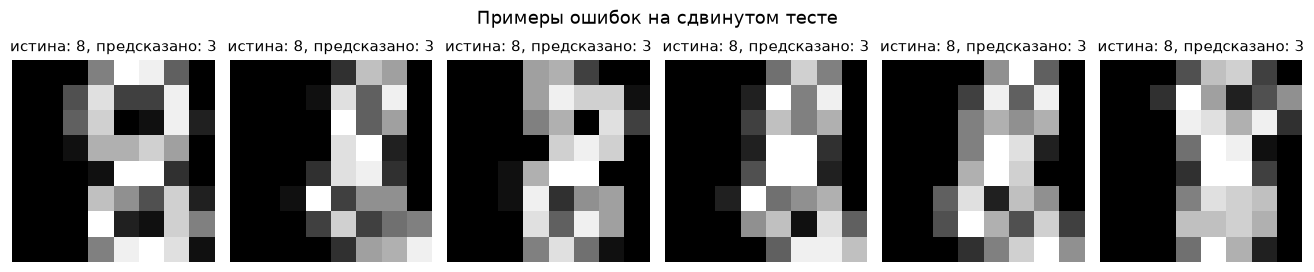

In [8]:
X_train_img, X_test_img, X_train_flat, X_test_flat, y_train, y_test = train_test_split(
    X_img, X_flat, y,
    test_size=0.25,
    stratify=y,
    random_state=42,
)

model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_flat, y_train)

y_pred = model.predict(X_test_flat)
accuracy_original = accuracy_score(y_test, y_pred)
print(f'Accuracy на исходном тесте: {accuracy_original:.3f}')

X_test_shifted = np.zeros_like(X_test_img)
X_test_shifted[:, :, 1:] = X_test_img[:, :, :-1]

X_test_shifted_flat = X_test_shifted.reshape(len(X_test_shifted), -1)

y_pred_shifted = model.predict(X_test_shifted_flat)
accuracy_shifted = accuracy_score(y_test, y_pred_shifted)
print(f'Accuracy на сдвинутом тесте (сдвиг вправо на 1 px): {accuracy_shifted:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], colorbar=False)
axes[0].set_title(f'Исходный тест, accuracy = {accuracy_original:.3f}')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_shifted, ax=axes[1], colorbar=False)
axes[1].set_title(f'Сдвинутый тест (вправо на 1 px), accuracy = {accuracy_shifted:.3f}')
fig.tight_layout()
plt.show()

wrong_idx = np.where(y_pred_shifted != y_test)[0]
print(f'Ошибок на сдвинутом тесте: {len(wrong_idx)} из {len(y_test)}')

n_examples = min(6, len(wrong_idx))
fig, axes = plt.subplots(1, n_examples, figsize=(2.2 * n_examples, 2.8))
for ax, idx in zip(np.atleast_1d(axes), wrong_idx[:n_examples]):
    ax.imshow(X_test_shifted[idx], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'истина: {y_test[idx]}, предсказано: {y_pred_shifted[idx]}', fontsize=11)
    ax.axis('off')
fig.suptitle('Примеры ошибок на сдвинутом тесте', fontsize=13)
fig.tight_layout()
plt.show()


на обычном тесте accuracy = 0.978, после сдвига на пиксель вправо - 0.656. flatten привязан к позиции пикселей, поэтому все 31 ошибка после сдвига - восьмёрки, прочитанные как тройки.
